# Load the Confidence Head and Predict

This notebook is a template for the eval team. It loads a confidence head that [`train-head.ipynb`](train-head.ipynb) trained, rebuilds the head's inputs from a cache, and predicts `p_error` for a few val images. The scores belong to the eval runner, which can start from the code here. [`cache-tutorial.ipynb`](cache-tutorial.ipynb) explains the arrays of the cache, and the introduction of `train-head.ipynb` explains what the head learns.

### The Head in Brief

For every cell of the cache grid, the head outputs one logit. `torch.sigmoid` turns it into `p_error`, the predicted probability that the Depth Anything V2 depth in the cell is off by more than `tau`, measured as the AbsRel against lidar. The head reads one input tensor `x` per camera image, which `ConfidenceDataset` builds from the cache along with the lidar labels:

| Key of an item | Shape | What it is |
|---|---|---|
| `x` | (C, h, w) | the input of the head |
| `abs_rel` | (1, h, w) | the AbsRel of the depth against lidar, per cell |
| `target` | (1, h, w) | 1 where `abs_rel` is above `tau` |
| `mask` | (1, h, w) | 1 where a lidar point lands in the cell; the other cells have no `abs_rel` and no `target` |
| `key` | str | the entry key, such as `scene-0103_020_CAM_FRONT` |

The training read only official train scenes, so val is free for the scores.

> **Note.** The outputs saved in this notebook come from a head trained on the v1.0-mini cache. They show that the code runs.

## Setup

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from torch.utils.data import DataLoader, Subset

from confhead import Cache, ConfidenceDataset, load_head
from confhead.geometry import grid_centers
from confhead.plot import draw_map, draw_points

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

# The confhead folder: the nearest parent that holds configs/ and pyproject.toml.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir() and (p / "pyproject.toml").is_file())


def table(headers, rows):
    """Rows as a markdown table."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    return Markdown("\n".join(lines))

**Settings to change:**

| Setting | Default | Effect |
|---|---|---|
| `CHECKPOINT` | `None` | The checkpoint to load. `None` takes the newest `best.pt` in your runs folder: `/scratch1/$USER/confhead-runs` on CARC, `outputs/runs` elsewhere. To load a teammate's run, set its path, for example `"/scratch1/<user>/confhead-runs/<run>/best.pt"`. |
| `CACHE_ROOT` | `None` | The cache to predict on. `None`: the cache that the head trained on. |
| `DATAROOT` | `None` | Where the nuScenes images are, for the figures. `None`: the folder the cache was built from. |
| `TAG` | `"val"` | The split to predict on |
| `N_IMAGES` | 3 | Images to predict, spread evenly over the split |

In [2]:
CHECKPOINT = None
CACHE_ROOT = None
DATAROOT = None
TAG = "val"
N_IMAGES = 3

## 1. Load the Head

`load_head(path, device)` returns three things:

1. the head in eval mode, with the input statistics of its train split
2. the `HeadInputs` of the training: the channel groups of `x`, `tau`, and the radar settings
3. a dict with the other fields of the checkpoint:

| Field | What it holds |
|---|---|
| `channels` | the names of the channels of `x`, in order |
| `cache` | the cache of the training: its root, fingerprint, grid, and Depth Anything settings |
| `epoch` | the epoch of this checkpoint |
| `history` | the train and dev loss of each epoch up to this one |
| `pos_weight` | the weight of the positive cells in the loss |
| `git` | the commit of the code that trained the head |

The loss weighted the positive cells by `pos_weight`, so where the weight is above 1, `p_error` runs higher than the true chance of an error, while the order of the cells stays the same.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
if CHECKPOINT is None:
    scratch = Path("/scratch1") / os.environ.get("USER", "")
    runs = scratch / "confhead-runs" if scratch.is_dir() else PROJECT / "outputs/runs"
    found = sorted(runs.glob("*/best.pt"), key=lambda p: p.stat().st_mtime)
    if not found:
        raise FileNotFoundError(f"no best.pt under {runs}; set CHECKPOINT, or train a head with train-head.ipynb")
    CHECKPOINT = found[-1]

head, inputs, info = load_head(CHECKPOINT, device)
print(f"checkpoint  {CHECKPOINT}")
print(f"epoch       {info['epoch']}, dev loss {info['history'][-1]['dev_loss']:.4f}, pos_weight {info['pos_weight']:.3f}, git {info['git']}")
print(f"inputs      {len(info['channels'])} channels: {', '.join(info['channels'][-4:])} and {len(info['channels']) - 4} more")
print(f"labels      tau {inputs.labels.tau}, align {inputs.labels.align}")
print(f"trained on  {info['cache']['root']} (fingerprint {info['cache']['fingerprint']}, grid {info['cache']['grid']})")
print(f"device      {device}")

checkpoint  /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/runs/nuscenes-mini-g2-20261028-1057/best.pt
epoch       8, dev loss 0.5966, pos_weight 1.686, git 51c2941-dirty
inputs      68 channels: depth, temporal_relstd, radar_residual, radar_valid and 64 more
labels      tau 0.1, align lidar
trained on  /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/cache/nuscenes-mini-g2 (fingerprint e43e53bcb50cb85f, grid [132, 74])
device      mps


## 2. Rebuild the Inputs

A head works only on inputs built the way its training inputs were: from the same Depth Anything layer, with the same `HeadInputs`. `ConfidenceDataset(cache, inputs, tag=TAG)` builds them, and its `channel_names` must equal the checkpoint's `channels`. The code below checks the names, and warns when the cache comes from another build than the training cache. On another grid the head still runs, because it is convolutional, but its 3x3 windows then cover another area of the image.

In [4]:
if CACHE_ROOT is None:
    CACHE_ROOT = info["cache"]["root"]
cache = Cache(CACHE_ROOT, DATAROOT)
data = ConfidenceDataset(cache, inputs, tag=TAG)
if data.channel_names != info["channels"]:
    raise ValueError(f"{cache.root} gives other channels than the head was trained on; "
                     "use a cache built with the same model settings")
if cache.header["fingerprint"] != info["cache"]["fingerprint"]:
    print(f"warning: {cache.root} is another build than the training cache; compare the settings in cache.json")
print(f"{len(data)} {TAG} images in {cache.root}, {len(data.channel_names)} channels as in training")

486 val images in /Users/nathanaday/projects/usc/kqiao-cs566-project-repo/confhead/outputs/cache/nuscenes-mini-g2, 68 channels as in training


## 3. Predict

The head takes a batch of `x` and returns one logit per cell. `predict` runs it over a `DataLoader` and yields one dict per image: `p_error` on every cell, and `abs_rel`, `target`, and `mask` from the lidar, each as an (h, w) array. A full eval runner would loop over the whole split the same way. Here, `N_IMAGES` images spread over the split are enough to show the output.

In [5]:
@torch.no_grad()
def predict(head, loader):
    """One dict per image: key, and p_error, abs_rel, target, mask as (h, w) arrays; mask is boolean."""
    for batch in loader:
        p_error = torch.sigmoid(head(batch["x"].to(device))).cpu().numpy()[:, 0]
        for i, key in enumerate(batch["key"]):
            yield {"key": key, "p_error": p_error[i], "abs_rel": batch["abs_rel"][i, 0].numpy(),
                   "target": batch["target"][i, 0].numpy(), "mask": batch["mask"][i, 0].numpy() > 0}


picks = np.linspace(0, len(data) - 1, N_IMAGES).round().astype(int).tolist()
images = list(predict(head, DataLoader(Subset(data, picks), batch_size=N_IMAGES)))

rows = {r["key"]: r for r in data.rows}
display(table(["key", "condition", "weather", "grid (h, w)", "labeled cells", "p_error from", "to"], [
    (im["key"], rows[im["key"]]["condition"], rows[im["key"]]["weather"], im["p_error"].shape, int(im["mask"].sum()),
     f"{im['p_error'].min():.3f}", f"{im['p_error'].max():.3f}") for im in images]))

| key | condition | weather | grid (h, w) | labeled cells | p_error from | to |
|---|---|---|---|---|---|---|
| scene-0103_000_CAM_BACK | day | clear | (74, 132) | 2094 | 0.001 | 1.000 |
| scene-0916_000_CAM_BACK_RIGHT | day | clear | (74, 132) | 2622 | 0.017 | 0.998 |
| scene-0916_040_CAM_FRONT_RIGHT | day | clear | (74, 132) | 2637 | 0.001 | 0.996 |

## 4. Look at the Predictions

Each row shows the camera image with its lidar points, the lidar AbsRel on the labeled cells, and `p_error` on every cell. A good head gives a high `p_error` where the AbsRel is high.

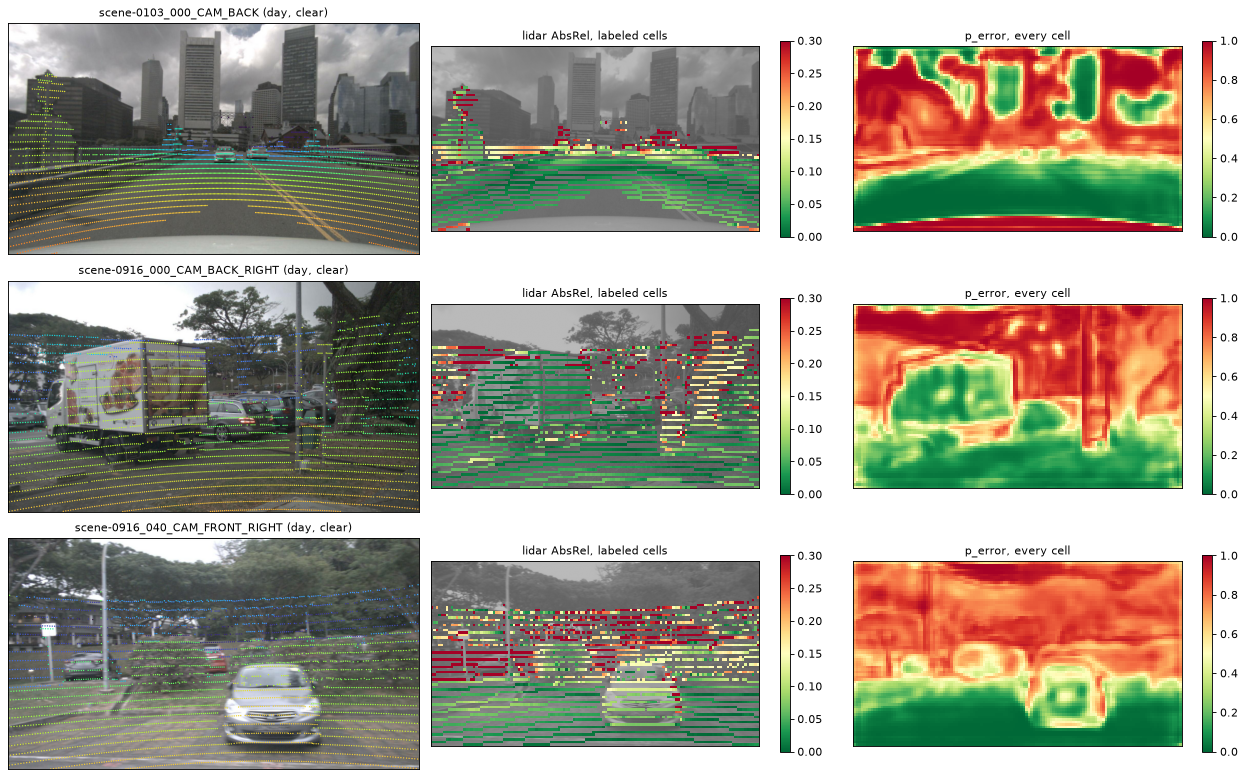

In [6]:
tau = inputs.labels.tau
fig, axes = plt.subplots(len(images), 3, figsize=(16, 3.3 * len(images)), squeeze=False)
for row_axes, im in zip(axes, images):
    entry = cache.entry(im["key"])
    rgb = entry.image()
    size = (entry.meta["image"]["width"], entry.meta["image"]["height"])
    draw_points(row_axes[0], rgb, lidar=entry.load(["lidar"])["lidar"])
    row_axes[0].set_title(f"{im['key']} ({entry.meta['condition']}, {entry.meta['weather']})")
    shown = draw_map(row_axes[1], im["abs_rel"], size, image=rgb, mask=im["mask"], cmap="RdYlGn_r", vmin=0, vmax=3 * tau)
    row_axes[1].set_title("lidar AbsRel, labeled cells")
    fig.colorbar(shown, ax=row_axes[1], shrink=0.8)
    shown = draw_map(row_axes[2], im["p_error"], size, cmap="RdYlGn_r", vmin=0, vmax=1)
    row_axes[2].set_title("p_error, every cell")
    fig.colorbar(shown, ax=row_axes[2], shrink=0.8)
fig.tight_layout()

## 5. The Labeled Cells of One Image

A score compares `p_error` with the lidar error on the labeled cells of each image. The code below takes these cells out of one prediction as flat arrays of the same length. It also gives each cell its center in the pixels of the camera image, from `confhead.geometry.grid_centers`, for a figure or a check against the raw lidar. The scene, the camera, the condition, and the weather of the image are in its row of `cache.rows()`.

In [7]:
im = images[0]
m = im["mask"]
entry = cache.entry(im["key"])
h, w = m.shape
u, v = grid_centers((w, h), (entry.meta["image"]["width"], entry.meta["image"]["height"]))
cell_row, cell_col = np.nonzero(m)
cells = {"p_error": im["p_error"][m], "abs_rel": im["abs_rel"][m], "target": im["target"][m], "u": u[m], "v": v[m]}

print(f"{im['key']}: {m.sum()} labeled cells of {m.size}; each array has shape {cells['p_error'].shape}")
display(table(["row", "col", "u (px)", "v (px)", "p_error", "abs_rel", "target"], [
    (cell_row[i], cell_col[i], f"{cells['u'][i]:.1f}", f"{cells['v'][i]:.1f}", f"{cells['p_error'][i]:.3f}",
     f"{cells['abs_rel'][i]:.3f}", int(cells["target"][i])) for i in range(5)]))

scene-0103_000_CAM_BACK: 2094 labeled cells of 9768; each array has shape (2094,)


| row | col | u (px) | v (px) | p_error | abs_rel | target |
|---|---|---|---|---|---|---|
| 16 | 12 | 151.0 | 200.2 | 0.970 | 0.615 | 1 |
| 16 | 13 | 163.1 | 200.2 | 0.962 | 0.052 | 0 |
| 16 | 14 | 175.3 | 200.2 | 0.956 | 0.052 | 0 |
| 17 | 14 | 175.3 | 212.3 | 0.969 | 0.617 | 1 |
| 17 | 15 | 187.4 | 212.3 | 0.964 | 8.267 | 1 |

## Where to Go Next

- [`src/confhead/head.py`](../src/confhead/head.py) holds `load_head` and the checkpoint format.
- [`src/confhead/dataset.py`](../src/confhead/dataset.py) builds `x` and the labels; `HeadInputs` and `LabelConfig` set `tau` and the fit behind the labels.
- `config.json` in the run folder of a checkpoint lists every setting of the training, including the dev scenes.
- [`guides/notebook-on-carc.md`](../guides/notebook-on-carc.md) opens the notebooks in JupyterLab on CARC.